## **Task 0 — Setup and Simulation**

### T0.1 Environment Setup

I installed the package and tested the environment.

Result: 104 passed, 10 deselected in 17.27s

### T0.2 Time Testing

CPU straight 10000 1.269 Actual device: cpu
CPU straight 100000 12.706 Actual device: cpu
CPU straight 200000 26.482 Actual device: cpu
CPU straight 1000000 118.351 Actual device: cpu
CPU full 10000 2.267 Actual device: cpu
CPU full 100000 22.329 Actual device: cpu
CPU full 200000 38.744 Actual device: cpu
CPU full 1000000 198.022 Actual device: cpu
GPU straight 10000 0.455 Actual device: cuda
GPU straight 100000 1.506 Actual device: cuda
GPU straight 200000 2.826 Actual device: cuda
GPU straight 1000000 12.615 Actual device: cuda
GPU full 10000 0.568 Actual device: cuda
GPU full 100000 2.977 Actual device: cuda
GPU full 200000 5.656 Actual device: cuda
GPU full 1000000 28.113 Actual device: cuda


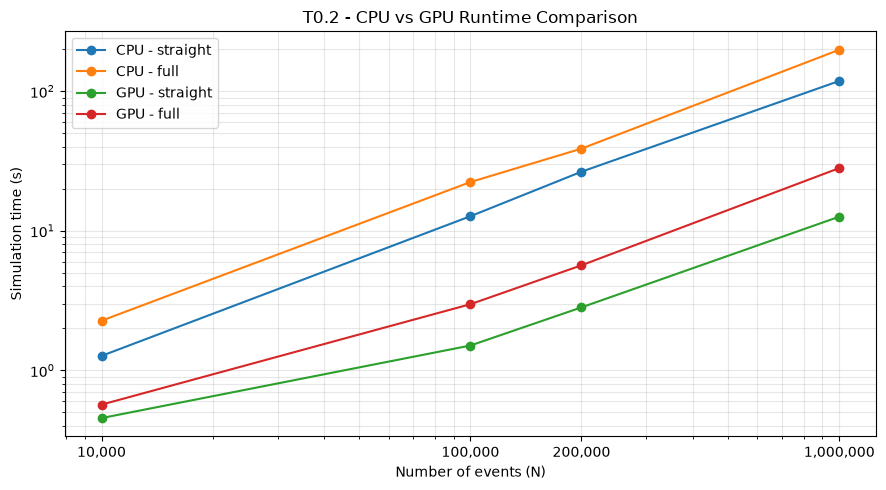

In [13]:
from pathlib import Path
import json
import h5py
import matplotlib.pyplot as plt

# 1. Set file paths and event counts
root = Path(".") if Path("TASKS.md").exists() else Path("..")
N = [10000, 100000, 200000, 1000000]

plt.figure(figsize=(9, 5))

# 2. Read CPU and GPU runtime data
for device, prefix in [("CPU", "t0_"), ("GPU", "t0_gpu_")]:
    for preset in ["straight", "full"]:
        times = []

        for n in N:
            file = root / "data" / f"{prefix}{preset}_n{n}.h5"

            with h5py.File(file, "r") as f:
                info = json.loads(f.attrs["provenance"])

            times.append(info["wall_time_s"])
            print(device, preset, n, times[-1],
                  "Actual device:", info["device"])

        plt.plot(N, times, marker="o", label=f"{device} - {preset}")

# 3. Plot settings
plt.xscale("log")
plt.yscale("log")
plt.xticks(N, ["10,000", "100,000", "200,000", "1,000,000"])

plt.xlabel("Number of events (N)")
plt.ylabel("Simulation time (s)")
plt.title("T0.2 - CPU vs GPU Runtime Comparison")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()

# 4. Save and display
plt.savefig(root / "notebooks" / "T0.2_simulation_time.png", dpi=300)
plt.show()

### T0.3 Data Structure

**Command:** `flashsim info data/flash_full_n10000_seed1.h5`

**Datasets and Shapes:**

* `truth/*`, `photons/*`: (10000,)
* `response/*`: (10000, 32)
* `detector/*`: (32,)

**Configuration:** `full` preset, seed = 1, CPU, 32 sensors. Configuration and provenance are stored as metadata.

**Photon Statistics:** 32.46% detected, 51.85% absorbed in bulk, 15.69% absorbed by walls.
